# Hadronic loss test
Read `particles_loss_t1e8_nH1.0_test.bin` and compare the final spectrum with the continuous-loss prediction.
Parameters below match `transport_hadronic_loss_test.cpp`: constant nH, equal-weight particles, and injected dN/dE ∝ E⁻¹.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.interpolate import PchipInterpolator
from scipy.stats import kstest, chi2

In [20]:
# Parameters used in transport_hadronic_loss_test.cpp
file = Path("particles_loss_t1e8_nH1.0_test.bin")
E_min = 10.0      # total energy, GeV
E_max = 1e6
m_p = 0.938272    # GeV
nH = 1.0         # cm^-3
t_end = 1e8       # yr
v_z = 3e-2       # pc / yr
c = 2.99792458e10 # cm / s
c_pc = 0.30660139 # pc / yr
yr2s = 31557600.0
N = 10000

# Binary records: x, y, z [pc], E [GeV]; native-endian float64
if file.stat().st_size == 0 or file.stat().st_size % 32:
    raise ValueError("Expected nonempty records of four float64 values")
data = np.fromfile(file, dtype="=f8").reshape(-1, 4)
x, y, z, E = data.T
n = len(E)
assert n == N, "Particle count does not match the run parameters"
assert np.isfinite(data).all() and np.all(E > m_p)

xyz = data[:, :3]
center = np.array([0, 0, v_z * t_end])
r = np.linalg.norm(xyz - center, axis=1)
print("Number of particles:", n)
print("E min / median / max [GeV]:", np.percentile(E, [0, 50, 100]))
print("Mean position [pc]:", xyz.mean(axis=0))
print("Expected center [pc]:", center)
print("Coordinate standard deviations [pc]:", xyz.std(axis=0, ddof=1))

Number of particles: 10000
E min / median / max [GeV]: [3.25248647e+00 6.04451253e+02 8.55180531e+04]
Mean position [pc]: [5.85306843e+02 9.73276590e+01 2.99971376e+06]
Expected center [pc]: [      0.       0. 3000000.]
Coordinate standard deviations [pc]: [27533.76196088 27703.01409884 27924.45862572]


In [21]:
# Cooling: dT/dt = -0.5 nH sigma_pp(T) c T, with T = E - m_p
# Integrate log(T) to keep the kinetic energy positive.
def sigma_pp(T):
    T = np.asarray(T, dtype=float)
    T_th = 0.2797
    T_safe = np.maximum(T, T_th)
    a = np.log(T_safe / T_th)
    sigma = (30.7 - 0.96 * a + 0.18 * a**2) * (1 - (T_th / T_safe)**1.9)**3 * 1e-27
    return np.where(T > T_th, sigma, 0.0)


def b(T):
    return 0.5 * nH * sigma_pp(T) * c * T * yr2s


def func(t, logT):
    T = np.exp(logT)
    return -b(T) / T


Ei = np.logspace(np.log10(E_min), np.log10(E_max), 4097)
sol = solve_ivp(func, (0, t_end), np.log(Ei - m_p), rtol=1e-10, atol=1e-12)
assert sol.success, sol.message
Ef = m_p + np.exp(sol.y[:, -1])
assert np.all(np.diff(Ef) > 0)

# Check the reference solver by tightening its tolerance.
sol_check = solve_ivp(func, (0, t_end), np.log(Ei - m_p), rtol=1e-12, atol=1e-13)
assert sol_check.success, sol_check.message
err = np.max(np.abs((m_p + np.exp(sol_check.y[:, -1])) / Ef - 1))
assert err < 1e-7
print("Reference solver relative difference:", err)
print("Predicted final energy range [GeV]:", Ef[[0, -1]])

Reference solver relative difference: 9.201683859316745e-11
Predicted final energy range [GeV]: [3.24973309e+00 8.58059139e+04]


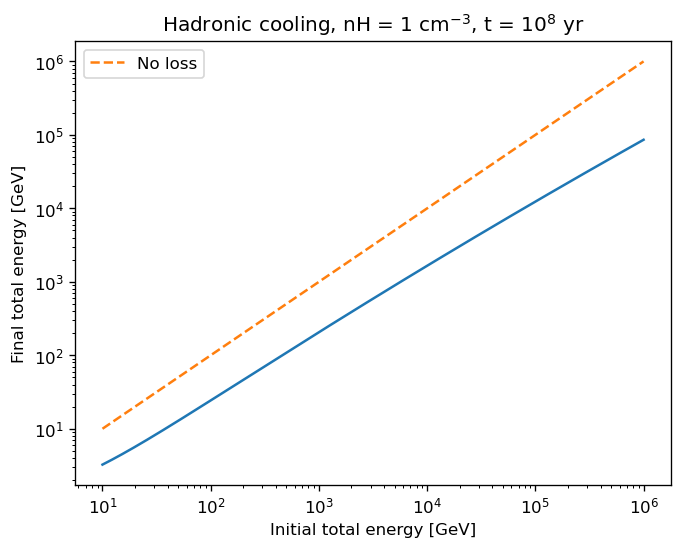

In [22]:
plt.plot(Ei, Ef)
plt.plot(Ei, Ei, linestyle="--", label="No loss")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Initial total energy [GeV]")
plt.ylabel("Final total energy [GeV]")
plt.legend()
plt.title("Hadronic cooling, nH = 1 cm$^{-3}$, t = $10^8$ yr")
plt.show()

In [29]:
# Invert the cooling map. Bin probabilities come from the initial CDF.
# For E^-1 injection: F(Ei) = ln(Ei / E_min) / ln(E_max / E_min).
inverse = PchipInterpolator(np.log(Ef), np.log(Ei), extrapolate=False)


def cdf(E, slope=1):
    E = np.asarray(E, dtype=float)
    E0 = np.exp(inverse(np.log(np.clip(E, Ef[0], Ef[-1]))))
    if slope == 1:
        F = np.log(E0 / E_min) / np.log(E_max / E_min)
    elif slope == 2:
        F = (1 / E_min - 1 / E0) / (1 / E_min - 1 / E_max)
    else:
        raise ValueError("Use injection slope 1 or 2")
    return np.where(E <= Ef[0], 0, np.where(E >= Ef[-1], 1, np.clip(F, 0, 1)))


bins = np.logspace(np.log10(min(E.min(), Ef[0], E_min) * 0.999),
                   np.log10(max(E.max(), E_max) * 1.001), 23)
counts, _ = np.histogram(E, bins=bins)
dE = np.diff(bins)
dlnE = np.diff(np.log(bins))
Ec = np.sqrt(bins[:-1] * bins[1:])
dnde = counts / dE
error = np.sqrt(counts) / dE

pred = n * np.diff(cdf(bins))
F0 = np.clip(np.log(bins / E_min) / np.log(E_max / E_min), 0, 1)
inj = n * np.diff(F0)
good = counts > 0
assert counts.sum() == n and np.isclose(pred.sum(), n)
print("Measured / predicted number:", counts.sum(), pred.sum())

Measured / predicted number: 10000 10000.000000000002


## Energy spectrum
Counts divided by **linear bin width** give dN/dE. E dN/dE has units of particles; E² dN/dE has units of GeV and is a different quantity.

The exact average of dN/dln E is counts / ln(E_upper/E_lower). It differs slightly from Ec × counts / dE for finite bins. A number density dn/dE additionally requires a specified volume. Here the file supplies particle counts only.

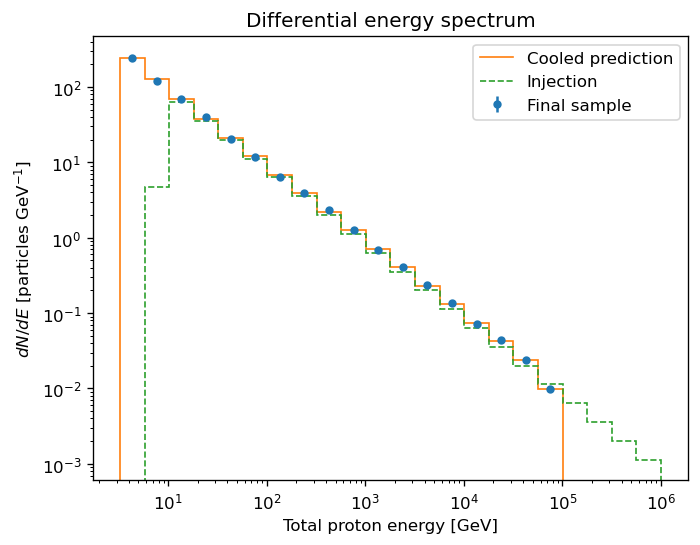

In [30]:
a = 1 / dE
plt.errorbar(Ec[good], (counts * a)[good], yerr=(np.sqrt(counts) * a)[good],
             fmt="o", ms=4, label="Final sample")
plt.stairs(pred * a, bins, label="Cooled prediction")
plt.stairs(inj * a, bins, linestyle="--", label="Injection")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Total proton energy [GeV]")
plt.ylabel(r"$dN/dE$ [particles GeV$^{-1}$]")
plt.legend()
plt.title("Differential energy spectrum")
plt.show()

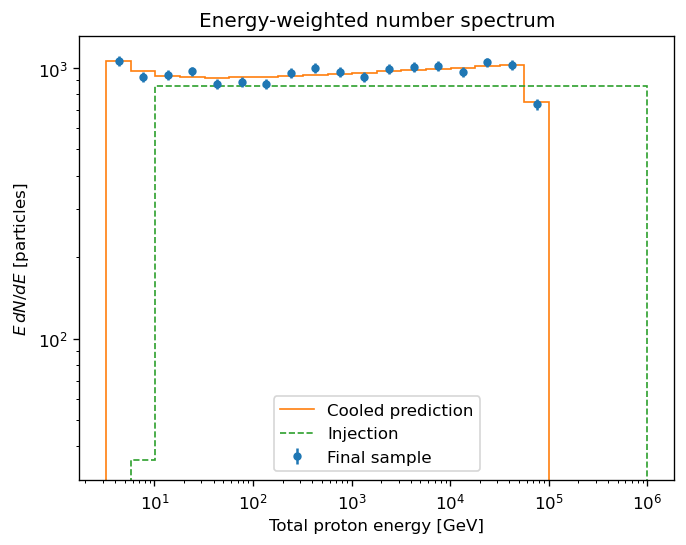

In [31]:
a = Ec / dE
plt.errorbar(Ec[good], (counts * a)[good], yerr=(np.sqrt(counts) * a)[good],
             fmt="o", ms=4, label="Final sample")
plt.stairs(pred * a, bins, label="Cooled prediction")
plt.stairs(inj * a, bins, linestyle="--", label="Injection")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Total proton energy [GeV]")
plt.ylabel(r"$E\,dN/dE$ [particles]")
plt.legend()
plt.title("Energy-weighted number spectrum")
plt.show()

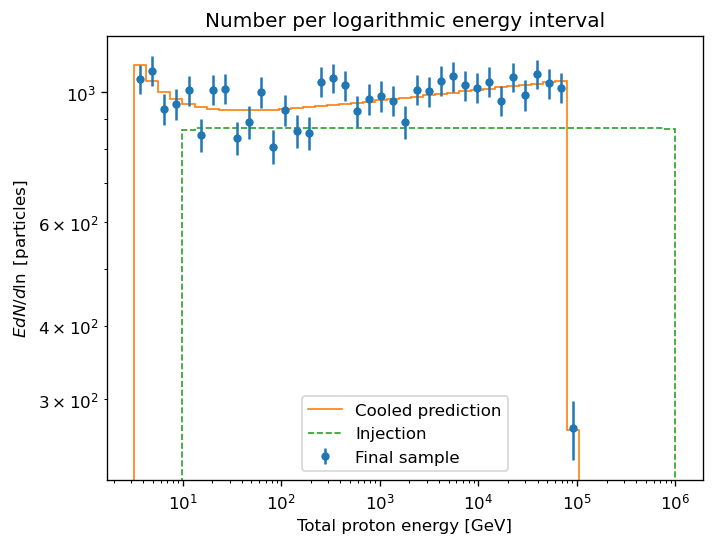

In [26]:
a = 1 / dlnE
plt.errorbar(Ec[good], (counts * a)[good], yerr=(np.sqrt(counts) * a)[good],
             fmt="o", ms=4, label="Final sample")
plt.stairs(pred * a, bins, label="Cooled prediction")
plt.stairs(inj * a, bins, linestyle="--", label="Injection")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Total proton energy [GeV]")
plt.ylabel(r"$E dN/d\ln $ [particles]")
plt.legend()
plt.title("Number per logarithmic energy interval")
plt.show()

In [27]:
# Distribution checks; parameters are fixed, not fitted to the binary.
support_ok = np.all((E >= Ef[0] * (1 - 1e-4)) & (E <= Ef[-1] * (1 + 1e-4)))
ks = kstest(E, cdf)
ks2 = kstest(E, lambda E: cdf(E, slope=2))

# Equal-probability bins keep the tails well sampled.
q = np.linspace(0, 1, 21)
qbins = np.interp(q, np.log(Ei / E_min) / np.log(E_max / E_min), Ef)
qbins[0] = min(qbins[0], E.min()) * (1 - 1e-9)
qbins[-1] = max(qbins[-1], E.max()) * (1 + 1e-9)
obs = np.histogram(E, bins=qbins)[0]
exp = n * np.diff(cdf(qbins))
stat = np.sum((obs - exp)**2 / exp)
p_value = chi2.sf(stat, len(exp) - 1)

print("All energies inside predicted support:", support_ok)
print(f"Cooled E^-1: KS D = {ks.statistic:.5f}, p = {ks.pvalue:.5f}")
print(f"Cooled E^-2: KS D = {ks2.statistic:.5f}, p = {ks2.pvalue:.5g}")
print(f"Binned test: chi2 = {stat:.3f}, df = {len(exp) - 1}, p = {p_value:.5f}")
print("Spectrum consistent at 1% significance:", support_ok and ks.pvalue > 0.01 and p_value > 0.01)

All energies inside predicted support: True
Cooled E^-1: KS D = 0.01013, p = 0.25435
Cooled E^-2: KS D = 0.70320, p = 0
Binned test: chi2 = 17.744, df = 19, p = 0.53958
Spectrum consistent at 1% significance: True


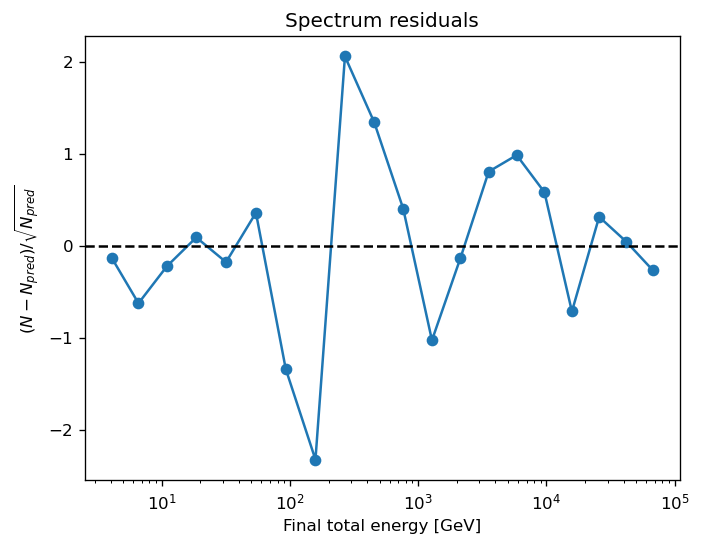

In [28]:
Eq = np.sqrt(qbins[:-1] * qbins[1:])
plt.plot(Eq, (obs - exp) / np.sqrt(exp), "o-")
plt.axhline(0, c="black", linestyle="--")
plt.xscale("log")
plt.xlabel("Final total energy [GeV]")
plt.ylabel(r"$(N - N_{pred}) / \sqrt{N_{pred}}$")
plt.title("Spectrum residuals")
plt.show()

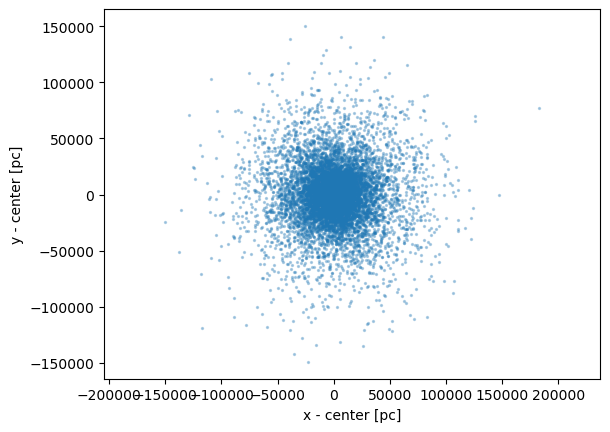

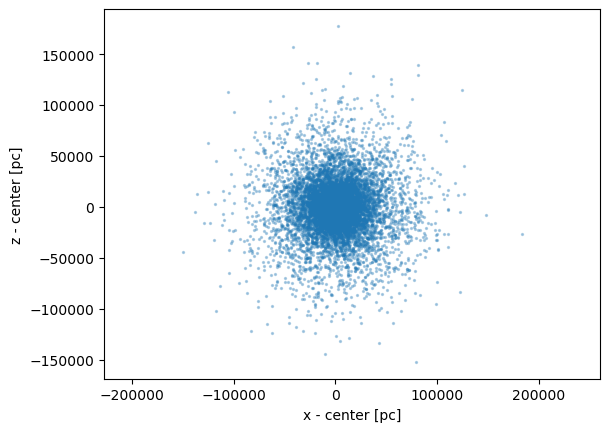

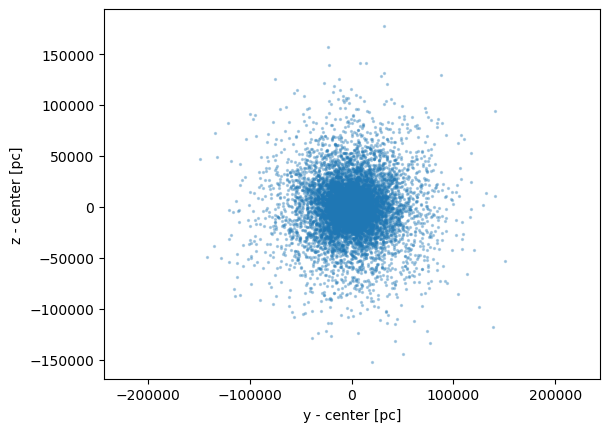

In [11]:
# Spatial projections, centered on the expected wind displacement
names = ["x", "y", "z"]
for i, j in [(0, 1), (0, 2), (1, 2)]:
    plt.figure()
    plt.scatter(xyz[:, i] - center[i], xyz[:, j] - center[j], s=2, alpha=0.3)
    plt.xlabel(names[i] + " - center [pc]")
    plt.ylabel(names[j] + " - center [pc]")
    plt.axis("equal")
    plt.show()

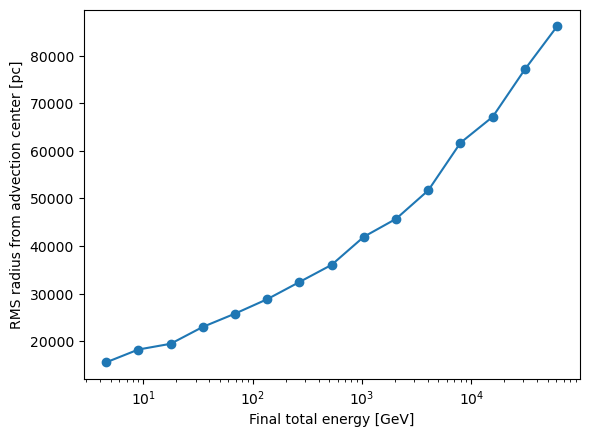

In [12]:
# RMS radius versus final energy
rbins = np.logspace(np.log10(E.min() * 0.999), np.log10(E.max() * 1.001), 16)
nr = np.histogram(E, bins=rbins)[0]
r2 = np.histogram(E, bins=rbins, weights=r**2)[0]
Er = np.sqrt(rbins[:-1] * rbins[1:])
rms = np.sqrt(np.divide(r2, nr, out=np.full_like(r2, np.nan), where=nr > 0))
good_r = nr >= 20
plt.plot(Er[good_r], rms[good_r], "o-")
plt.xscale("log")
plt.xlabel("Final total energy [GeV]")
plt.ylabel("RMS radius from advection center [pc]")
plt.show()

## Diffusion check
The full-step update has D = λ²/(6 dt) = c λ/3, for λ = 2 E^(1/3) pc and dt = λ/(2c). Spatial variance measures the **time average** during cooling, so it can exceed D at the final energy. The source retains a full displacement for the final truncated timestep.

In [13]:
min_count = 30
pc2cm = 3.0856775814913673e18
yr2s = 31557600.0
D_unit = pc2cm**2 / yr2s  # pc²/yr -> cm²/s

raw = np.fromfile(file, dtype='=f8')
if raw.size == 0 or raw.size % 4:
    raise ValueError('Expected nonempty (x, y, z, E) float64 records.')
data_D = raw.reshape(-1, 4)
if not np.isfinite(data_D).all() or np.any(data_D[:, 3] <= 0):
    raise ValueError('Positions and positive total energies must be finite.')
if len(data_D) < min_count or t_end <= 0:
    raise ValueError('Need more particles and a positive simulation duration.')
xyz_D = data_D[:, :3]
E_D = data_D[:, 3]

def lmd(e):
    return 2.0 * np.asarray(e)**(1 / 3)

def D_physical(e):
    return c_pc * lmd(e) / 3.0

def D_step(e):
    length = lmd(e)
    timestep = length / (2.0 * c_pc)
    return length**2 / (6.0 * timestep)

# Include the maximum-energy particle in the last bin.
Dbins = np.geomspace(E_D.min() * 0.999,
                               E_D.max() * 1.001, 13)
rows = []
for lower, upper in zip(Dbins[:-1], Dbins[1:]):
    selected = (E_D >= lower) & (E_D < upper)
    count = int(selected.sum())
    if count < min_count:
        continue
    centered = xyz_D[selected] - xyz_D[selected].mean(axis=0)
    square = centered**2
    # ddof=1 correction for the sample coordinate variances.
    d_axes = square.sum(axis=0) / (count - 1) / (2.0 * t_end)
    per_particle_d = square.sum(axis=1) / (6.0 * t_end)
    correction = count / (count - 1)
    d_error = per_particle_d.std(ddof=1) / np.sqrt(count) * correction
    d_reference = D_physical(E_D[selected]).mean()
    rows.append((np.exp(np.log(E_D[selected]).mean()),
                           count, *d_axes, d_axes.mean(), d_error, d_reference))
if not rows:
    raise ValueError('No sufficiently populated energy bins; reduce the bin count.')
result = np.asarray(rows)
e_bin, counts_bin, dx, dy, dz, d_measured, d_error, d_final = result.T
E_grid = np.geomspace(E_D.min(), E_D.max(), 200)

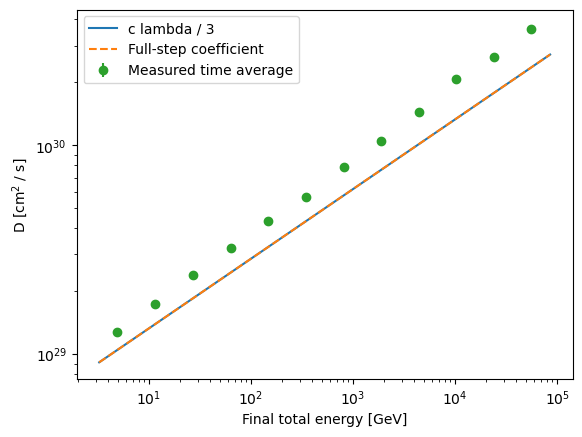

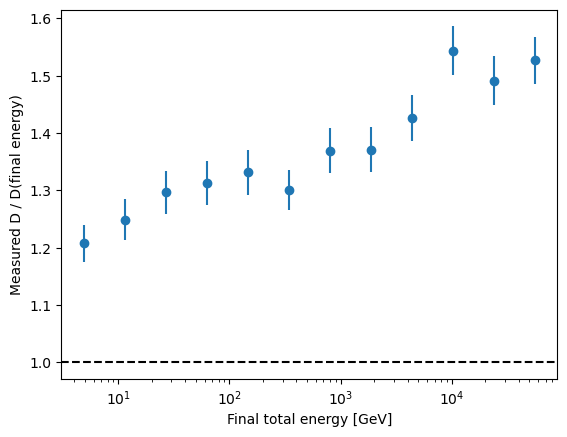

In [14]:
plt.plot(E_grid, D_physical(E_grid) * D_unit, label="c lambda / 3")
plt.plot(E_grid, D_step(E_grid) * D_unit, linestyle="--", label="Full-step coefficient")
plt.errorbar(e_bin, d_measured * D_unit, yerr=d_error * D_unit,
             fmt="o", label="Measured time average")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Final total energy [GeV]")
plt.ylabel("D [cm$^2$ / s]")
plt.legend()
plt.show()

plt.errorbar(e_bin, d_measured / d_final, yerr=d_error / d_final, fmt="o")
plt.axhline(1, c="black", linestyle="--")
plt.xscale("log")
plt.xlabel("Final total energy [GeV]")
plt.ylabel("Measured D / D(final energy)")
plt.show()

## Interpretation
The statistical checks compare the output with the current source equation and assumed run parameters. They do not establish the physical accuracy of the cross section or per-particle numerical errors. The binary contains no initial energies or run metadata. A timestep refinement run is needed to quantify Euler integration bias. Counting error bars use √N; KS and Pearson tests assume independent initial draws.

In [32]:
# Parameters used in transport_hadronic_loss_test.cpp
file = Path("particles_loss_t1e8_nH1.0_test_1.bin")
E_min = 10.0      # total energy, GeV
E_max = 1e6
m_p = 0.938272    # GeV
nH = 1.0         # cm^-3
t_end = 1e8       # yr
v_z = 3e-2       # pc / yr
c = 2.99792458e10 # cm / s
c_pc = 0.30660139 # pc / yr
yr2s = 31557600.0
N = 10000

# Binary records: x, y, z [pc], E [GeV]; native-endian float64
if file.stat().st_size == 0 or file.stat().st_size % 32:
    raise ValueError("Expected nonempty records of four float64 values")
data = np.fromfile(file, dtype="=f8").reshape(-1, 4)
x, y, z, E = data.T
n = len(E)
assert n == N, "Particle count does not match the run parameters"
assert np.isfinite(data).all() and np.all(E > m_p)

xyz = data[:, :3]
center = np.array([0, 0, v_z * t_end])
r = np.linalg.norm(xyz - center, axis=1)
print("Number of particles:", n)
print("E min / median / max [GeV]:", np.percentile(E, [0, 50, 100]))
print("Mean position [pc]:", xyz.mean(axis=0))
print("Expected center [pc]:", center)
print("Coordinate standard deviations [pc]:", xyz.std(axis=0, ddof=1))

Number of particles: 10000
E min / median / max [GeV]: [206.20192687 206.20192687 206.20192687]
Mean position [pc]: [ 3.93352113e+02 -1.04087583e+02  2.99992690e+06]
Expected center [pc]: [      0.       0. 3000000.]
Coordinate standard deviations [pc]: [17869.04719834 18019.07875596 17834.32588026]


In [39]:
Ei = np.array([1000])
sol = solve_ivp(func, (0, t_end), np.log(Ei - m_p), rtol=1e-10, atol=1e-12)
# assert sol.success, sol.message
Ef = m_p + np.exp(sol.y[:, -1])
# assert np.all(np.diff(Ef) > 0)

In [40]:
sol

  message: The solver successfully reached the end of the integration interval.
  success: True
   status: 0
        t: [ 0.000e+00  2.111e-01 ...  8.495e+07  1.000e+08]
        y: [[ 6.907e+00  6.907e+00 ...  5.555e+00  5.324e+00]]
      sol: None
 t_events: None
 y_events: None
     nfev: 74
     njev: 0
      nlu: 0

In [41]:
Ef

array([206.20199282])

In [56]:
data = np.fromfile("particles_loss_t1e8_nH1.0_test2.bin", dtype="=f8").reshape(-1, 4)
x, y, z, E = data.T
Ei = np.logspace(1,6,51)
sol = solve_ivp(func, (0, t_end), np.log(Ei - m_p), rtol=1e-10, atol=1e-12)
# assert sol.success, sol.message
Ef = m_p + np.exp(sol.y[:, -1])
(Ef - E)/Ef

array([3.86013434e-08, 4.48846207e-08, 5.14808397e-08, 5.84193799e-08,
       6.57503274e-08, 7.35368842e-08, 8.18542101e-08, 9.07861178e-08,
       1.00425051e-07, 1.10872945e-07, 1.22240771e-07, 1.34648727e-07,
       1.48229345e-07, 1.63126347e-07, 1.79498121e-07, 1.97519671e-07,
       2.17382510e-07, 2.39297882e-07, 2.63500269e-07, 2.90247043e-07,
       3.19824855e-07, 3.52549388e-07, 3.88770874e-07, 4.28877759e-07,
       4.73298961e-07, 5.22510502e-07, 5.77040090e-07, 6.37471330e-07,
       7.04451206e-07, 7.78696256e-07, 8.60999689e-07, 9.52240088e-07,
       1.05338976e-06, 1.16552507e-06, 1.28983668e-06, 1.42764206e-06,
       1.58039795e-06, 1.74971582e-06, 1.93737683e-06, 2.14534974e-06,
       2.37580969e-06, 2.63116006e-06, 2.91405439e-06, 3.22742376e-06,
       3.57450321e-06, 3.95886314e-06, 4.38444244e-06, 4.85558686e-06,
       5.37708893e-06, 5.95423139e-06, 6.59283844e-06])

In [54]:
E

array([3.24973296e+00, 3.87759451e+00, 4.66896141e+00, 5.66294802e+00,
       6.90831546e+00, 8.46570394e+00, 1.04103795e+01, 1.28356146e+01,
       1.58568461e+01, 1.96167799e+01, 2.42916546e+01, 3.00989147e+01,
       3.73066048e+01, 4.62448583e+01, 5.73199355e+01, 7.10313631e+01,
       8.79928437e+01, 1.08957741e+02, 1.34850121e+02, 1.66802529e+02,
       2.06201927e+02, 2.54745511e+02, 3.14508487e+02, 3.88026290e+02,
       4.78394269e+02, 5.89388436e+02, 7.25611634e+02, 8.92670334e+02,
       1.09738833e+03, 1.34806483e+03, 1.65478595e+03, 2.02980035e+03,
       2.48797202e+03, 3.04732536e+03, 3.72970137e+03, 4.56154654e+03,
       5.57486096e+03, 6.80833677e+03, 8.30872435e+03, 1.01324705e+04,
       1.23476816e+04, 1.50364744e+04, 1.82977891e+04, 2.22507532e+04,
       2.70387021e+04, 3.28339795e+04, 3.98436671e+04, 4.83164180e+04,
       5.85506001e+04, 7.09039960e+04, 8.58053482e+04])

In [49]:
E

array([9.99473496e+00, 1.25155664e+01, 1.58255598e+01, 1.98936657e+01,
       2.49785759e+01, 3.13920866e+01, 3.95317275e+01, 4.98357036e+01,
       6.29105017e+01, 7.91471847e+01, 9.94951070e+01, 1.25081371e+02,
       1.58412515e+02, 1.98712428e+02, 2.50782220e+02, 3.15476675e+02,
       3.97675219e+02, 5.00507089e+02, 6.26906804e+02, 7.94036578e+02,
       9.99694961e+02, 1.25667680e+03, 1.58160031e+03, 1.99227004e+03,
       2.50415968e+03, 3.16144619e+03, 3.97132597e+03, 4.98384642e+03,
       6.30376770e+03, 7.93224104e+03, 9.99448841e+03, 1.25814062e+04,
       1.58360950e+04, 1.98585538e+04, 2.50935597e+04, 3.15733148e+04,
       3.97255549e+04, 4.99960639e+04, 6.29236194e+04, 7.93042468e+04,
       9.96629392e+04, 1.25790206e+05, 1.58283335e+05, 1.99160415e+05,
       2.50091619e+05, 3.15860412e+05, 3.97508537e+05, 4.99773196e+05,
       6.29634498e+05, 7.92985058e+05, 9.96019571e+05])